In [6]:
#Step 1: Import necessary libraries for visualization, processing, metrics, and modeling
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [7]:
#Step 2: Load the Iris dataset and convert it into a pandas DataFrame
iris = load_iris()

x = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(x, columns=feature_names)
df['target'] = y
df["target_name"] = [target_names[i] for i in y]

print("Dataset shape: ", df.shape)
df.head()

Dataset shape:  (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [8]:
#Step 3: Inspect dataset feature names, target classes and class distribution
print("feature names: ")
print(feature_names)

print("\ntarget names: ")
print(target_names)

print("\nClass distribution:")
print(df["target"].value_counts())

feature names: 
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

target names: 
['setosa' 'versicolor' 'virginica']

Class distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [9]:
#Step 4: Split the dataset into stratified training (80%) and testing (20%) sets
X_train, X_test , y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("training samples:", X_train.shape[0])
print("testing samples:", X_test.shape[0])

training samples: 120
testing samples: 30


In [10]:
#Step 5: Standardize features using StandardScaler fitted on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled[:5])

[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [11]:
#Step 6: Reduce standardized features to 2 dimensions using PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original Number of features: ", X_train.shape[1])
print("Reduced Number of features: ", X_train_pca.shape[1])

print("\nExplained Variance Ratio: ")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance: ")
print(sum(pca.explained_variance_ratio_))

Original Number of features:  4
Reduced Number of features:  2

Explained Variance Ratio: 
[0.72677234 0.23066667]

Total Explained Variance: 
0.9574390106545363


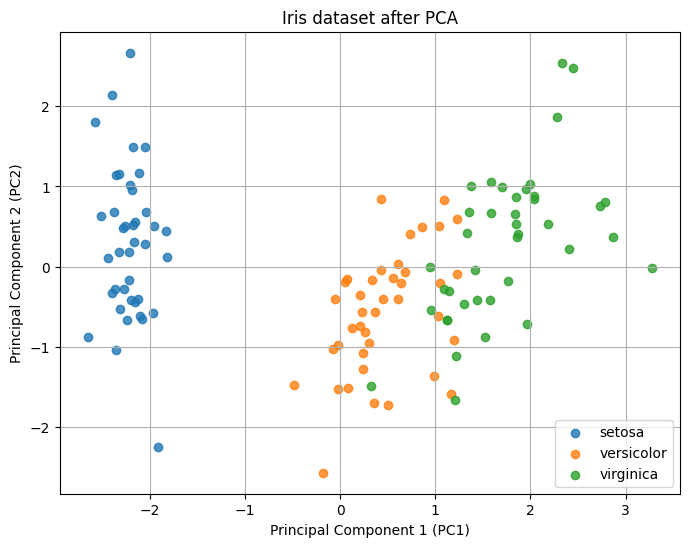

In [12]:
#Step 7: Visualize the 2D PCA-reduced training data using a scatter plot
plt.figure(figsize=(8, 6))

for class_value, class_name in enumerate(target_names):
    plt.scatter(
        X_train_pca[y_train == class_value, 0],
        X_train_pca[y_train == class_value, 1],
        label=class_name,
        alpha=0.8
    )

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("Iris dataset after PCA")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
#Step 8: Train a Logistic Regression model on PCA features and make predictions
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)
print("Predicted Classes")
print(y_pred)

Predicted Classes
[0 1 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 2 2 2 1 0 2 0]


In [14]:
#Step 9: Calculate and print overall classification metrics for the PCA model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

results = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
        "Score": [accuracy, precision, recall, f1],
    }
)

results["Score"] = results["Score".strip()].round(4)

print(results.to_string(index=False))

   Metric  Score
 Accuracy 0.9000
Precision 0.9024
   Recall 0.9000
 F1 Score 0.8997


In [15]:
#Step 10: Print classification report with precision, recall, and F1-score for the PCA model
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



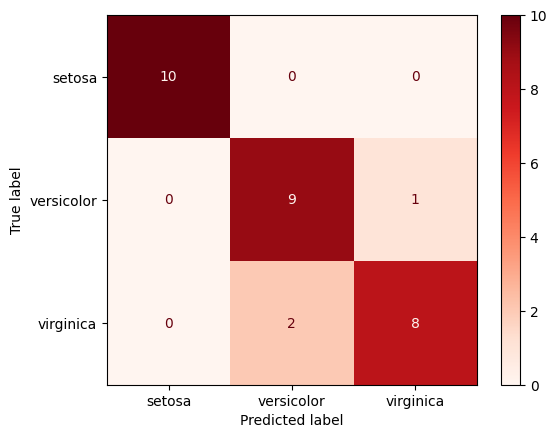

In [16]:
#Step 11: Generate and plot the confusion matrix for the PCA model predictions
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap=plt.cm.Reds, values_format="d")

In [17]:
#Step 12: Train a Logistic Regression model on the original features and predict
original_model = LogisticRegression(max_iter=1000, random_state=42)
original_model.fit(X_train, y_train)

y_pred_original = original_model.predict(X_test)
print("Predicted Classes")
print(y_pred_original)

Predicted Classes
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [18]:
#Step 13: Print classification report with precision, recall, and F1-score for original features model
print(classification_report(y_test, y_pred_original, target_names=target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [19]:
#Step 14: Calculate and print overall classification metrics for the original features model
accuracy = accuracy_score(y_test, y_pred_original)
precision = precision_score(y_test, y_pred_original, average="macro")
recall = recall_score(y_test, y_pred_original, average="macro")
f1 = f1_score(y_test, y_pred_original, average="macro")

results = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
        "Score": [accuracy, precision, recall, f1],
    }
)

results["Score"] = results["Score"].round(4)

print(results.to_string(index=False))

   Metric  Score
 Accuracy 0.9667
Precision 0.9697
   Recall 0.9667
 F1 Score 0.9666


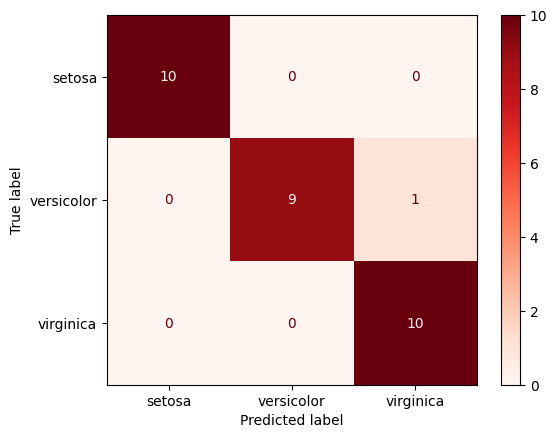

In [20]:
#step 15: Generate and plot the confusion matrix for the original features model
cm = confusion_matrix(y_test, y_pred_original)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap=plt.cm.Reds, values_format="d")